# Trayectorias por entidad

Exploración abierta: cada código de acreedor conserva su identidad. La clasificación fintech anterior no se usa para seleccionar observaciones ni para agregar resultados. Personas y firmas se estudian por separado. El universo agregado describe escala; la muestra de personas permite estudiar transiciones y comparar relaciones dentro del mismo deudor-mes.

Los saldos son stocks, no originaciones. Situaciones 3–5, 3–6 y 2–6 se calculan explícitamente: son definiciones operativas, no una validación de comparabilidad regulatoria entre entidades. Un saldo fuera de esos rangos tampoco equivale a crédito nuevo. Las fuentes conservan una historia retrospectiva, susceptible a bajas, cesiones y rectificaciones.

**Primera lectura de la corrida del 21/09/2026.** Las entidades muestran trayectorias distintas aun dentro de las etiquetas anteriores: MercadoLibre expande saldo y clientes, Brubank aumenta clientes con saldo casi plano y Ualá contrae ambos. Algunos bancos divergen entre personas y firmas. El salto de Galicia exige tratar la continuidad del código 150; la comparación dentro del deudor también varía por entidad. El código legal tiene soporte mínimo. Ver `resultados_por_entidad.md` para magnitudes, límites y agenda. Estas conclusiones corresponden a los insumos registrados en `05_inputs.json`; revisar al cambiar los datos.

**Ampliación 22/09/2026.** La expansión de Creditech de abril incluye mayormente reapariciones de relaciones en la muestra; los saltos de ICBC y Patagonia en firmas tienen mayor concentración en pocos deudores. Las cohortes con entidad focal y otros bancos muestran compensaciones parciales y caídas conjuntas, sin una dirección única. Ver las secciones finales y la nota de resultados para magnitudes y límites.

In [1]:
from pathlib import Path
import sys, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from IPython.display import display, Markdown
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'Data/processed/ipc.dta').exists())
sys.path.insert(0, str(root/'Code/analysis/liquidez_fintech'))
from common import CENDEU, DATA, HERE, OUT, BASELINE, connect, price_index, figure_style, time_axis, save_figure, record_inputs
figure_style()
pd.set_option('display.max_rows', 22)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
con=connect()
labels=pd.read_csv(root/'Data/crosswalks/cendeu_lenders.csv')[['ent','name','group','regulator_class']]
assert labels.ent.is_unique
ipc=price_index()
paths=sorted((CENDEU/'person_lender_5pct').glob('*.parquet'))
record_inputs(paths+list((CENDEU/'lender_month').glob('*.parquet'))+[DATA/'ipc.dta',DATA/'balances_bancos.dta',root/'Data/crosswalks/cendeu_lenders.csv'],'05')
def attach_names(frame):
    result=frame.merge(labels,on='ent',how='left',validate='many_to_one')
    result['name']=result.name.fillna('Sin nombre: '+result.ent.astype(str))
    return result


## Universo: personas y firmas, sin agrupar acreedores

Se preservan todos los códigos, incluso garantías y etiquetas dudosas; no se interpreta su suma como crédito neto. El archivo por entidad permite revisar esas etiquetas después. Los deudores son los registros `active` del reshape (saldo o situación positiva); no se suman entre entidades como personas únicas. El saldo real llega hasta el último IPC disponible.

In [2]:
universe=con.execute("SELECT * FROM read_parquet(?)",[str(CENDEU/'lender_month/*.parquet')]).fetchdf()
assert not universe.duplicated(['ent','year','month','borrower_type']).any()
universe['fecha']=pd.to_datetime(dict(year=universe.year,month=universe.month,day=1))
universe=attach_names(universe).merge(ipc[['fecha','deflactor']],on='fecha',how='left',validate='many_to_one')
universe['real']=universe.credit_ars*universe.deflactor
universe['outside35_real']=(universe.credit_ars-universe.npl_ars)*universe.deflactor
universe['bad_share']=100*universe.npl_ars/universe.credit_ars.replace(0,np.nan)
universe['ticket_real']=universe.real/universe.borrowers.replace(0,np.nan)
universe.to_csv(OUT/'05_universo_entidad.csv',index=False)
last=universe.loc[universe.deflactor.notna(),'fecha'].max()
display(universe.groupby('borrower_type').agg(entidades=('ent','nunique'),desde=('fecha','min'),hasta=('fecha','max')))
# Selección gráfica por tamaño previo, no por etiqueta fintech ni crecimiento posterior.
top={kind:universe.loc[universe.fecha.eq(BASELINE)&universe.borrower_type.eq(kind)].nlargest(12,'credit_ars').ent.tolist() for kind in ['person','firm']}


,entidades,desde,hasta
borrower_type,,,
firm,306,2024-08-01,2026-07-01
other,25,2024-08-01,2026-07-01
person,547,2024-08-01,2026-07-01


## El camino del saldo y de los clientes

Doce mayores entidades por saldo de mayo de 2025 en cada población. Cada línea se normaliza por su propia base; las escalas verticales son comunes dentro de cada lámina. La selección no excluye caídas ni entidades que dejan de reportar. Una línea interrumpida indica ausencia, no cero. La línea vertical solo marca la base de normalización, no un efecto causal.

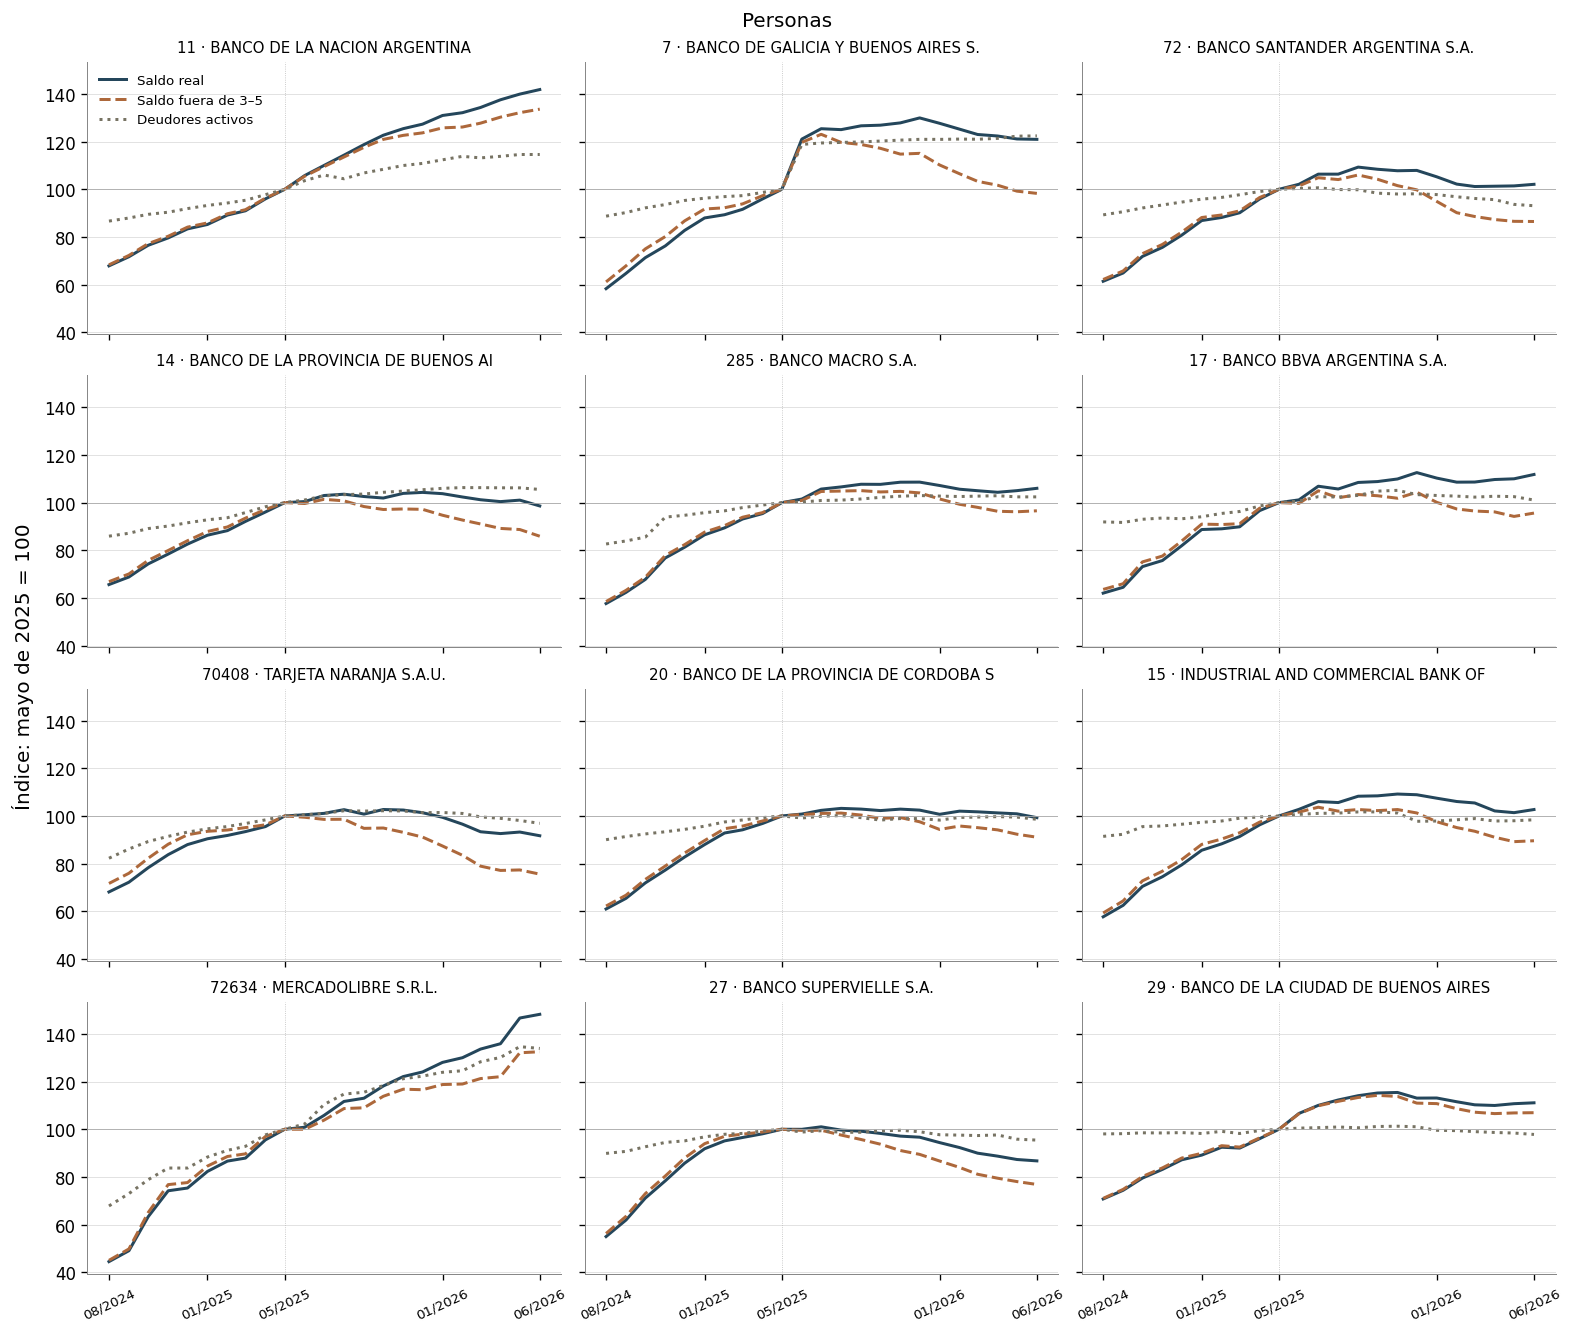

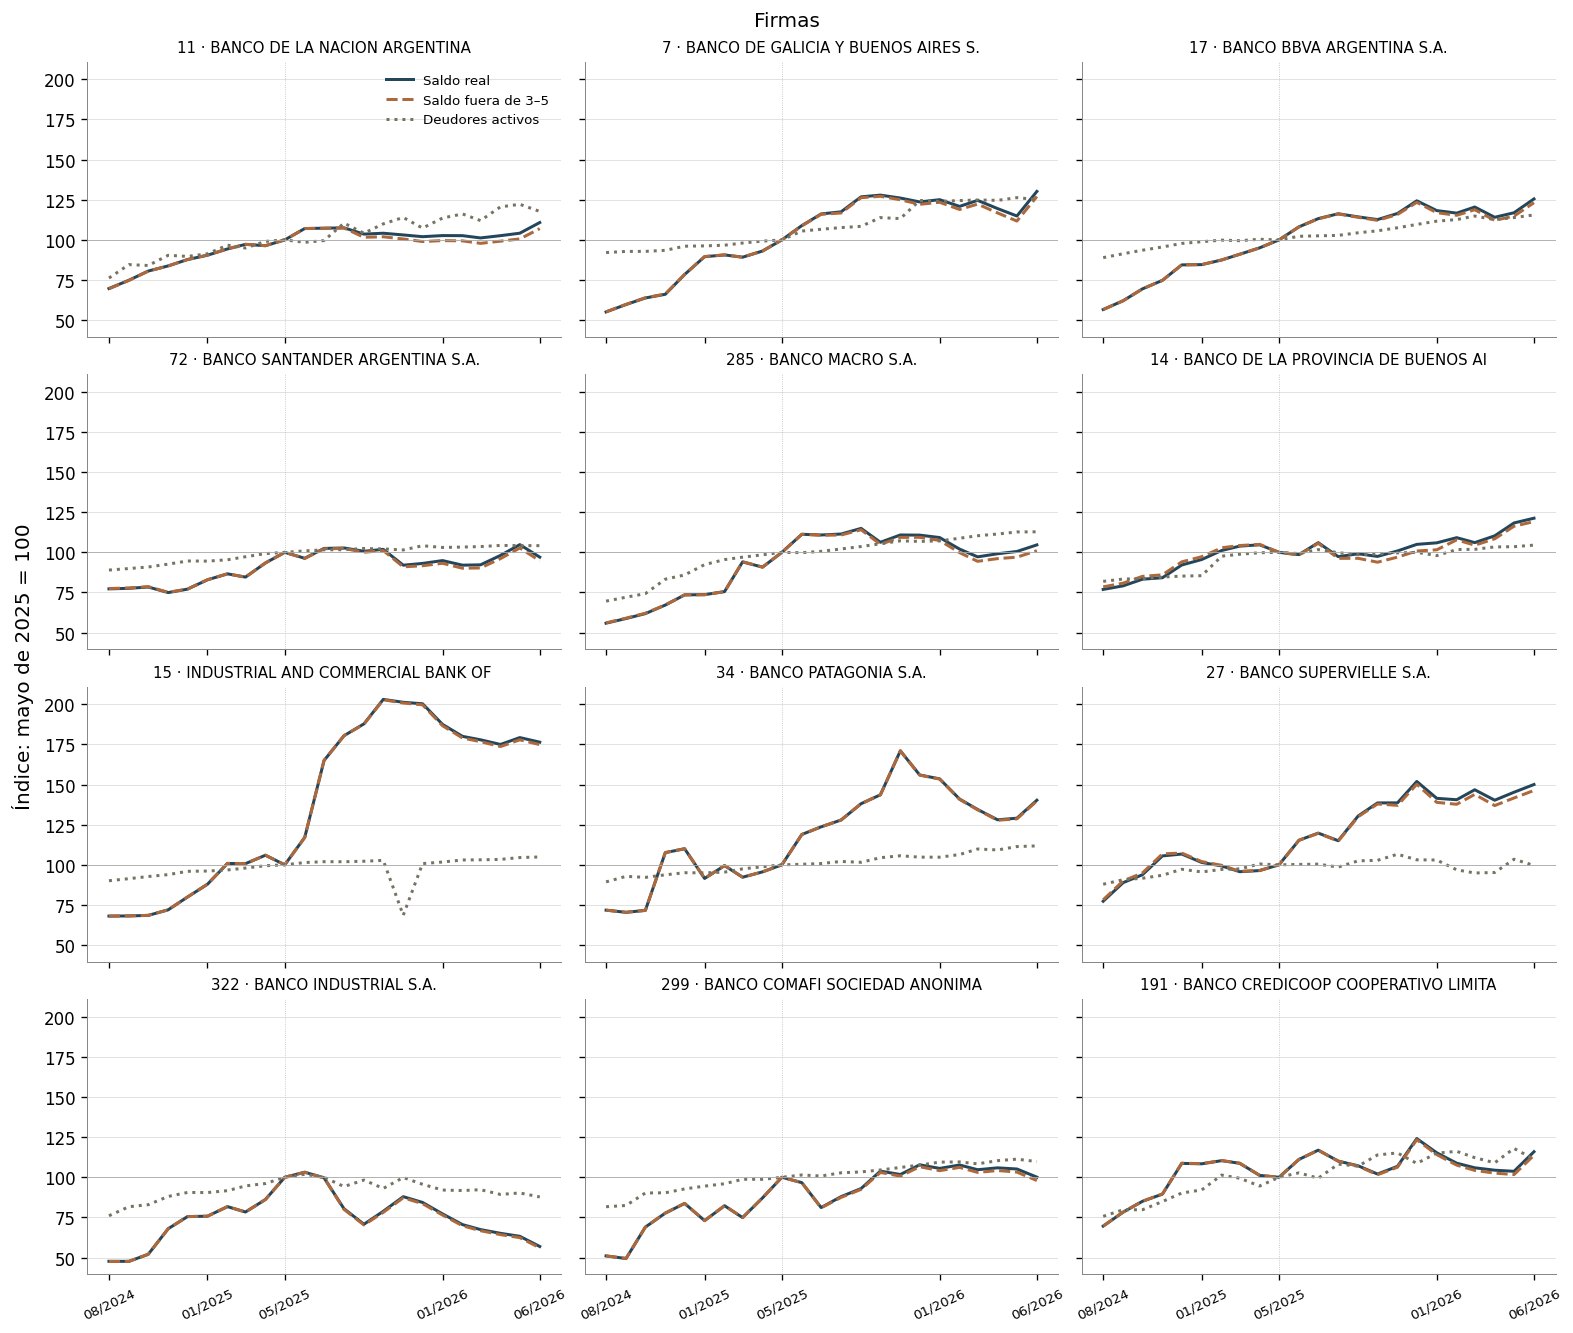

In [3]:
def trajectory_page(ids,kind):
    fig,axes=plt.subplots(4,3,figsize=(13,11),sharex=True,sharey=True,layout='constrained')
    for ax,ent in zip(axes.flat,ids):
        d=universe.loc[universe.ent.eq(ent)&universe.borrower_type.eq(kind)&universe.deflactor.notna()].sort_values('fecha').set_index('fecha')
        b=d.loc[BASELINE]
        for col,label,color,ls in [('real','Saldo real','#24465B','-'),('outside35_real','Saldo fuera de 3–5','#AD683B','--'),('borrowers','Deudores activos','#777363',':')]:
            if b[col]>0: ax.plot(d.index,100*d[col]/b[col],label=label,color=color,linestyle=ls)
        ax.set_title(f'{ent} · {str(b["name"])[:34]}',fontsize=9)
        ax.axhline(100,color='#aaa',lw=.5); ax.axvline(BASELINE,color='#bbb',lw=.5,ls=':'); time_axis(ax,d.index)
        ax.tick_params(axis='x',labelsize=8,rotation=25)
    for ax in list(axes.flat)[len(ids):]: ax.set_visible(False)
    axes[0,0].legend(fontsize=8)
    fig.supylabel('Índice: mayo de 2025 = 100')
    fig.suptitle('Personas' if kind=='person' else 'Firmas')
    return fig
for kind in ['person','firm']:
    fig=trajectory_page(top[kind],kind);save_figure(fig,'05_trayectorias_'+kind);plt.show()


## Entidades vinculadas a las preguntas del proyecto

Selección nominal para inspección, sin sumar ni definir un grupo: MercadoLibre, Tarjeta Naranja, Naranja Digital, Ualá, Brubank, Reba, Credicuotas, Crédito Directo, Moni y Creditech. El atlas conserva el resto de las entidades. La coexistencia de crecimiento y contracción dentro de esta selección es justamente lo que una etiqueta única puede ocultar.

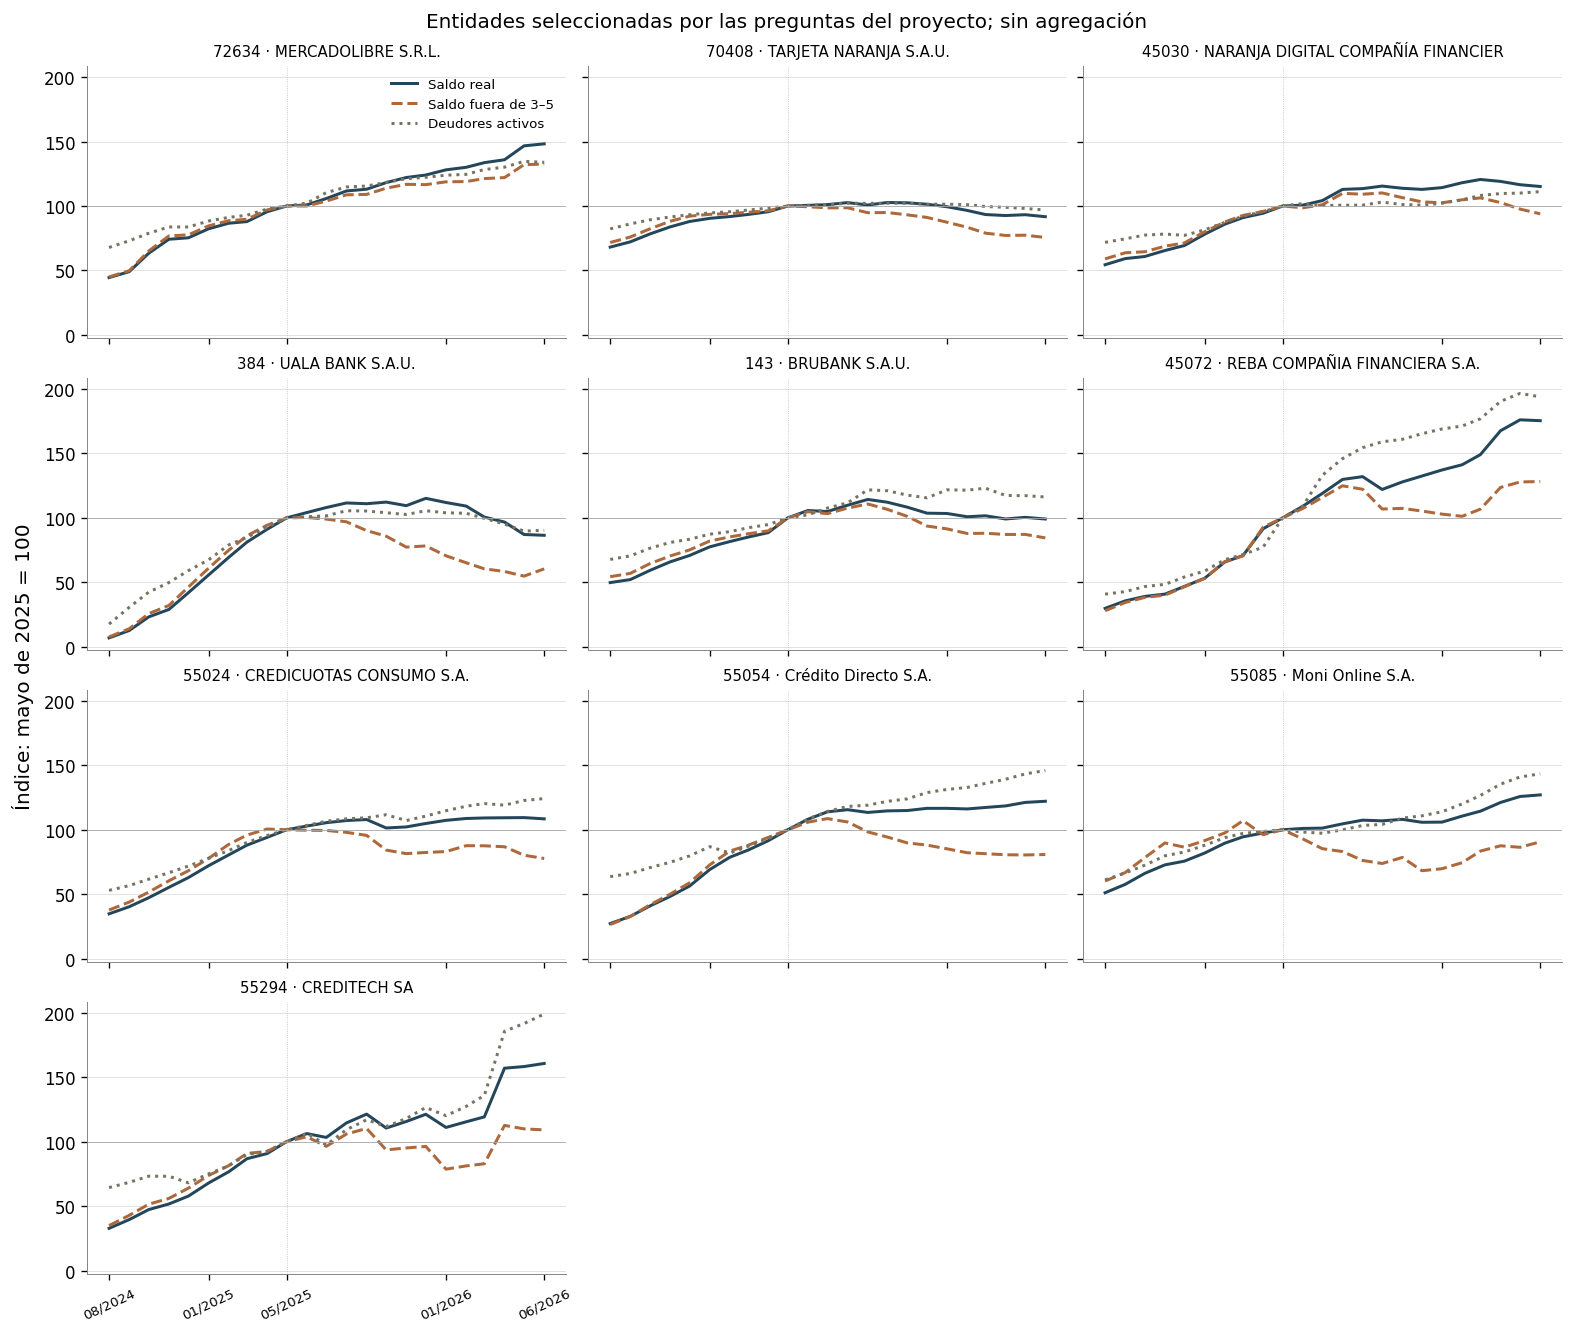

In [4]:
named_entities=[72634,70408,45030,384,143,45072,55024,55054,55085,55294]
fig=trajectory_page(named_entities,'person')
fig.suptitle('Entidades seleccionadas por las preguntas del proyecto; sin agregación')
save_figure(fig,'05_entidades_seleccionadas');plt.show()


## Fichero completo y atlas

Se exportan las trayectorias de todas las entidades. El atlas adicional incluye cada entidad con al menos 1.000 deudores activos y saldo positivo en mayo de 2025, ordenada por código; no usa su categoría. Esto facilita explorar financieras, cooperativas y entidades digitales sin encerrarlas en una bolsa residual.

In [5]:
endpoint=universe.loc[universe.fecha.eq(last)].copy()
base=universe.loc[universe.fecha.eq(BASELINE)].copy()
summary=base[['ent','borrower_type','name','group','real','outside35_real','borrowers','bad_share']].merge(endpoint[['ent','borrower_type','real','outside35_real','borrowers','bad_share']],on=['ent','borrower_type'],how='outer',suffixes=('_base','_end'),validate='one_to_one')
for col in ['real','outside35_real','borrowers']:
    summary[col+'_growth']=100*(summary[col+'_end']/summary[col+'_base'].replace(0,np.nan)-1)
summary['bad_pp']=summary.bad_share_end-summary.bad_share_base
summary.to_csv(OUT/'05_cambios_entidad.csv',index=False)
with PdfPages(OUT/'05_atlas_entidades.pdf') as pdf:
    for kind in ['person','firm']:
        ids=base.loc[base.borrower_type.eq(kind)&base.borrowers.ge(1000)&base.credit_ars.gt(0)].sort_values('ent').ent.tolist()
        for start in range(0,len(ids),12):
            fig=trajectory_page(ids[start:start+12],kind);pdf.savefig(fig);plt.close(fig)
display(summary.loc[summary.borrower_type.eq('person')].nlargest(18,'real_base')[['ent','name','real_growth','outside35_real_growth','borrowers_growth','bad_share_base','bad_share_end']])


,ent,name,real_growth,outside35_real_growth,borrowers_growth,bad_share_base,bad_share_end
5,11,BANCO DE LA NACION ARGENTINA,41.85,33.64,14.61,2.47,8.11
2,7,BANCO DE GALICIA Y BUENOS AIRES S.A.,20.96,-1.71,22.42,8.88,25.95
37,72,BANCO SANTANDER ARGENTINA S.A.,2.09,-13.50,-6.90,5.10,19.60
8,14,BANCO DE LA PROVINCIA DE BUENOS AIRES,-1.40,-14.10,5.53,4.13,16.48
87,285,BANCO MACRO S.A.,6.00,-3.43,2.41,3.25,11.86
16,17,BANCO BBVA ARGENTINA S.A.,11.81,-4.39,1.08,6.49,20.04
790,70408,TARJETA NARANJA S.A.U.,-8.30,-24.41,-3.10,8.37,24.46
19,20,BANCO DE LA PROVINCIA DE CORDOBA S.A.,-0.72,-8.93,-1.41,3.42,11.41
11,15,INDUSTRIAL AND COMMERCIAL BANK OF CHINA (ARGEN...,2.69,-10.40,-1.61,6.13,18.10
872,72634,MERCADOLIBRE S.R.L.,48.22,32.53,33.90,8.01,17.76


## Situaciones, código legal y comparación dentro de la persona

La muestra determinística del 5% se procesa mes a mes, sin expandirla. Se reportan saldos en situaciones 3–5, 3–6 y 2–6; la frecuencia del código legal igual a 1 se mide sobre relaciones con saldo positivo, con faltantes explícitos. Para personas con varias relaciones positivas se calcula situación 3–6 de cada relación menos la media de esa persona ese mes. Es un contraste descriptivo con la clientela compartida, no un coeficiente causal ni un ranking de tecnologías de cobro.

In [6]:
calendar=[]
for path in paths:
    periods=con.execute('SELECT DISTINCT year,month FROM read_parquet(?)',[str(path)]).fetchall()
    assert len(periods)==1
    y,m=periods[0];calendar.append((pd.Timestamp(y,m,1),path))
calendar=sorted(calendar)
assert len(calendar)==24 and all(calendar[i][0]+pd.offsets.MonthBegin(1)==calendar[i+1][0] for i in range(23))
monthly=[];transitions=[]
for i,(date,path) in enumerate(calendar):
    d=con.execute((HERE/'sql/entity_month.sql').read_text(),[str(path)]).fetchdf();d['fecha']=date;monthly.append(d)
    if i:
        t=con.execute((HERE/'sql/entity_transitions.sql').read_text(),[str(calendar[i-1][1]),str(path)]).fetchdf()
        t['fecha']=date;transitions.append(t)
entity=attach_names(pd.concat(monthly,ignore_index=True)).merge(ipc[['fecha','deflactor']],on='fecha',how='left',validate='many_to_one')
for col in ['bad35','bad36','bad26']: entity[col+'_pct']=100*entity[col]/entity.amount.replace(0,np.nan)
entity['within_pp']=100*entity.demeaned_sum/entity.shared_n.replace(0,np.nan)
entity['legal_pct']=100*entity.legal_n/(entity.positive_n-entity.legal_missing_n).replace(0,np.nan)
entity=entity.rename(columns={'legal_pct':'legal_code1_pct'})
entity.to_csv(OUT/'05_muestra_entidad.csv',index=False)
assert (entity.bad35<=entity.bad36).all() and (entity.bad36<=entity.bad26).all()
assert np.allclose(entity.groupby('fecha').demeaned_sum.sum(),0,atol=1e-7)
# Reconciliar muestra con auditoría anterior sería dependiente; se guarda todo para reproducción.
t=attach_names(pd.concat(transitions,ignore_index=True))
assert (t.curr_positive==t.continuing+t.first_observed+t.reappearing).all()
assert (t.prev_positive==t.continuing+t.to_zero+t.missing_row).all()
assert np.allclose(t.curr_amount,t.entry_amount+t.continuing_current)
assert np.allclose(t.prev_amount,t.exit_amount+t.continuing_previous)
t=t.merge(ipc[['fecha','deflactor']],on='fecha',how='left',validate='many_to_one')
prev_ipc=ipc[['fecha','deflactor']].copy();prev_ipc.fecha+=pd.offsets.MonthBegin(1);prev_ipc=prev_ipc.rename(columns={'deflactor':'prev_deflator'})
t=t.merge(prev_ipc,on='fecha',how='left',validate='many_to_one')
t['entry_real']=t.entry_amount*t.deflactor
t['exit_real']=-t.exit_amount*t.prev_deflator
t['continuing_change']=t.continuing_current*t.deflactor-t.continuing_previous*t.prev_deflator
t['delta_real']=t.curr_amount*t.deflactor-t.prev_amount*t.prev_deflator
valid=t.deflactor.notna()&t.prev_deflator.notna()
assert np.allclose(t.loc[valid,['entry_real','exit_real','continuing_change']].sum(axis=1),t.loc[valid,'delta_real'],atol=1)
for numerator,denominator,new in [('to_bad','prev_good','deterioration_pct'),('to_good','prev_bad','improvement_pct'),('exit_after_bad','prev_bad','exit_bad_pct'),('first_observed','curr_positive','first_pct'),('reappearing','curr_positive','reappearing_pct')]:
    t[new]=100*t[numerator]/t[denominator].replace(0,np.nan)
t.to_csv(OUT/'05_transiciones_entidad.csv',index=False)
display(pd.DataFrame({'control':['Filas ausentes tras saldo positivo','Faltantes del código legal con saldo','Diferencia saldo 3–6 menos 3–5'], 'valor':[t.missing_row.sum(),entity.legal_missing_n.sum(),(entity.bad36-entity.bad35).sum()]}))


,control,valor
0,Filas ausentes tras saldo positivo,0.00
1,Faltantes del código legal con saldo,0.00
2,Diferencia saldo 3–6 menos 3–5,0.00


## Auditorías que cambian la interpretación

El código `legal` se tabula sin asignarle significado judicial. Se compara además el peso de la muestra por entidad: representar cerca de 5% del saldo total no garantiza representatividad de cada entidad. Finalmente se verifica continuidad de personas entre los códigos 150 y 7 durante el salto de junio de 2025. La coincidencia es evidencia de continuidad del deudor, no prueba por sí sola la transferencia contractual de cada préstamo.

In [7]:
legal_dist=[]
for date,path in calendar:
    d=con.execute('SELECT legal,count(*) AS registros FROM read_parquet(?) GROUP BY legal',[str(path)]).fetchdf()
    d['fecha']=date;legal_dist.append(d)
legal_dist=pd.concat(legal_dist,ignore_index=True)
legal_dist.to_csv(OUT/'05_codigos_legal.csv',index=False)
display(legal_dist.groupby('legal',dropna=False).registros.sum().to_frame())
coverage=entity[['ent','fecha','amount','positive_n']].merge(universe.loc[universe.borrower_type.eq('person'),['ent','fecha','credit_ars']],on=['ent','fecha'],how='left',validate='one_to_one')
coverage['sample_amount_pct']=100*coverage.amount/coverage.credit_ars.replace(0,np.nan)
coverage.to_csv(OUT/'05_cobertura_por_entidad.csv',index=False)
display(attach_names(coverage.loc[coverage.ent.isin(named_entities)&coverage.fecha.isin([BASELINE,last])]).pivot(index='name',columns='fecha',values='sample_amount_pct'))
may_path=dict(calendar)[BASELINE];june_path=dict(calendar)[pd.Timestamp('2025-06-01')]
continuity=con.execute("""
WITH old AS (SELECT cuit,amount_ars FROM read_parquet(?) WHERE ent=150 AND amount_ars>0),
new AS (SELECT cuit,amount_ars FROM read_parquet(?) WHERE ent=7 AND amount_ars>0)
SELECT count(*) AS positivos_150_mayo,count(new.cuit) AS tambien_7_junio,
sum(old.amount_ars) AS saldo_150_mayo,
sum(CASE WHEN new.cuit IS NOT NULL THEN old.amount_ars ELSE 0 END) AS saldo_previo_coincidente
FROM old LEFT JOIN new USING(cuit)
""",[str(may_path),str(june_path)]).fetchdf()
continuity.to_csv(OUT/'05_continuidad_150_7.csv',index=False);display(continuity)
# Sensibilidad: sumar SALDOS de ambos códigos, sin sumar deudores únicos.
pair=universe.loc[universe.ent.isin([7,150])&universe.borrower_type.eq('person')].groupby('fecha')[['real','outside35_real']].sum(min_count=1)
pair_change=100*(pair.loc[last]/pair.loc[BASELINE]-1)
display(pair_change.rename('Cambio de saldos 7+150 (%)').to_frame())
pair.to_csv(OUT/'05_sensibilidad_saldos_7_150.csv')


,registros
legal,
0,54958672
1,25


fecha,2025-05-01,2026-06-01
name,,
BRUBANK S.A.U.,4.99,4.76
CREDICUOTAS CONSUMO S.A.,4.98,5.05
CREDITECH SA,5.15,5.03
Crédito Directo S.A.,4.94,4.84
MERCADOLIBRE S.R.L.,5.01,4.99
Moni Online S.A.,4.99,5.05
NARANJA DIGITAL COMPAÑÍA FINANCIERA S.A.U.,4.97,4.98
REBA COMPAÑIA FINANCIERA S.A.,4.04,5.09
TARJETA NARANJA S.A.U.,5.01,5.00


,positivos_150_mayo,tambien_7_junio,saldo_150_mayo,saldo_previo_coincidente
0,18234,17870,"50,074,846,000.00","49,911,068,000.00"


,Cambio de saldos 7+150 (%)
real,5.47
outside35_real,-15.35


## Deterioro y salida no son lo mismo

Selección: seis entidades de mayor saldo inicial más hasta seis códigos adicionales de mayor número de clientes que no estén ya incluidos. Todas se eligen en mayo, sin usar el resultado posterior. Las tasas de deterioro e inactividad tienen como denominador las relaciones con saldo positivo en el mes anterior y situación 1–2 o 3–6, respectivamente. La desaparición posterior a una situación adversa no prueba castigo; tampoco una reaparición prueba originación.

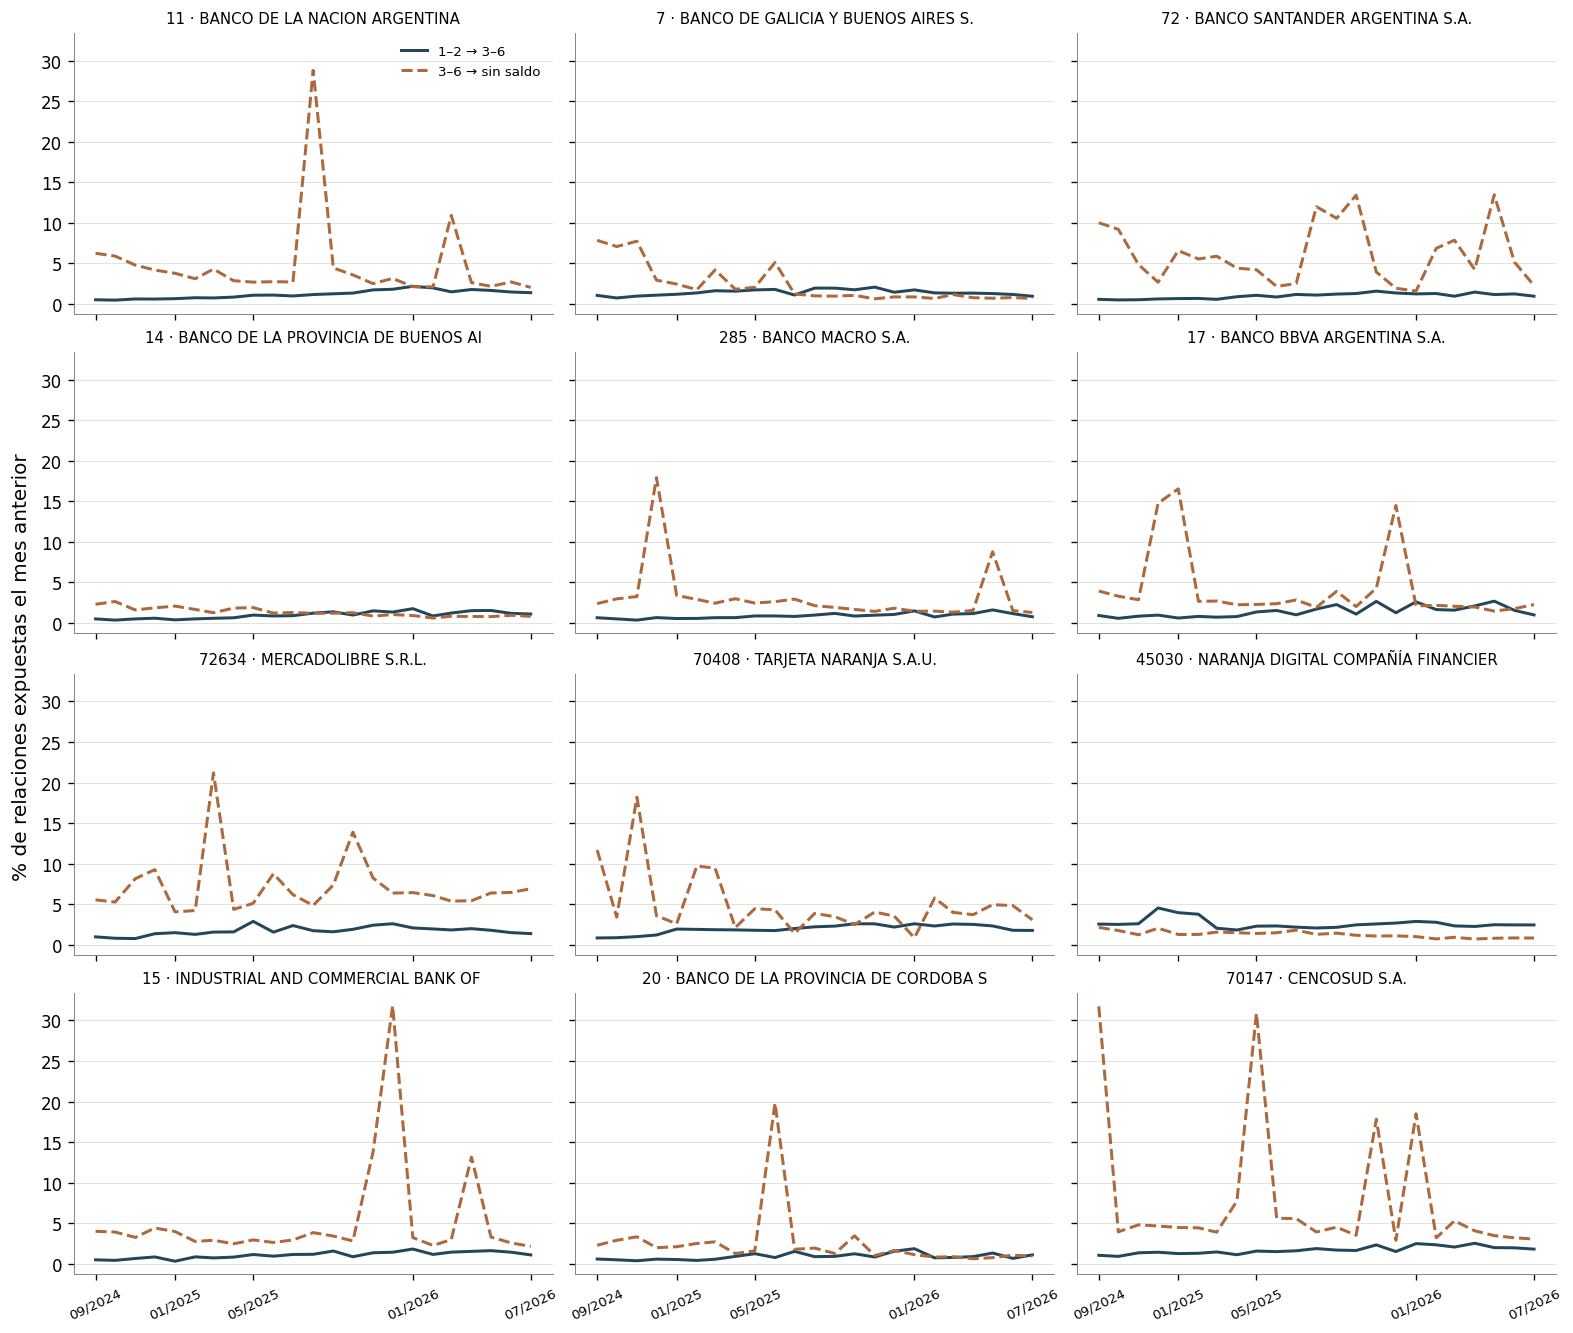

In [8]:
b=base.loc[base.borrower_type.eq('person')]
focus=top['person'][:6]+[x for x in b.sort_values('borrowers',ascending=False).ent if x not in top['person'][:6]][:6]
fig,axes=plt.subplots(4,3,figsize=(13,11),sharex=True,sharey=True,layout='constrained')
for ax,ent in zip(axes.flat,focus):
    d=t.loc[t.ent.eq(ent)].sort_values('fecha')
    ax.plot(d.fecha,d.deterioration_pct,label='1–2 → 3–6',color='#24465B')
    ax.plot(d.fecha,d.exit_bad_pct,label='3–6 → sin saldo',color='#AD683B',ls='--')
    ax.set_title(f'{ent} · {d.name.iloc[0][:34]}',fontsize=9);time_axis(ax,d.fecha);ax.tick_params(axis='x',labelsize=8,rotation=25)
axes[0,0].legend(fontsize=8);fig.supylabel('% de relaciones expuestas el mes anterior')
save_figure(fig,'05_deterioro_salidas');plt.show()


## ¿Cambian los resultados al comparar a la misma persona?

Cada punto identifica una entidad. Se exige al menos 500 relaciones compartidas en ambos meses para evitar que un puñado de casos ordene el gráfico. Se muestran todas las entidades que cumplen ese soporte, sin categorías. Un valor bajo puede reflejar producto, plazo, reporte, selección de la relación o cobro; no permite elegir entre esos mecanismos.

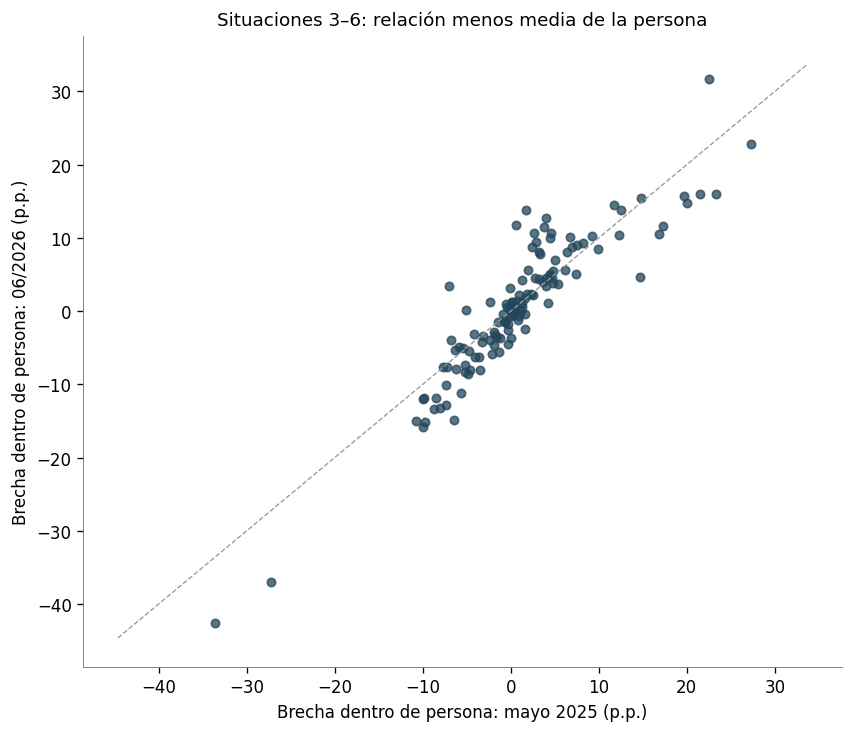

,ent,within_pp_2025_05,within_pp_2026_06,shared_n_2025_05,shared_n_2026_06,name,group,regulator_class
0,7,2.50,2.23,61571,80299,BANCO DE GALICIA Y BUENOS AIRES S.A.,banco_privado_nacional,financial_institution
1,11,-0.78,-1.29,67409,83905,BANCO DE LA NACION ARGENTINA,banco_publico,financial_institution
2,14,-0.40,0.59,46542,55647,BANCO DE LA PROVINCIA DE BUENOS AIRES,banco_publico,financial_institution
3,15,1.29,1.13,22101,23227,INDUSTRIAL AND COMMERCIAL BANK OF CHINA (ARGEN...,banco_privado_extranjero,financial_institution
4,17,0.95,2.21,66066,71828,BANCO BBVA ARGENTINA S.A.,banco_privado_extranjero,financial_institution
5,20,-1.92,-2.85,16686,18366,BANCO DE LA PROVINCIA DE CORDOBA S.A.,banco_publico,financial_institution
12,72,0.27,0.74,59124,60505,BANCO SANTANDER ARGENTINA S.A.,banco_privado_extranjero,financial_institution
22,285,-3.29,-4.19,57871,63337,BANCO MACRO S.A.,banco_privado_nacional,financial_institution
49,45030,3.95,3.45,75190,76150,NARANJA DIGITAL COMPAÑÍA FINANCIERA S.A.U.,cia_financiera_digital,finance_company
108,70147,1.67,1.73,23272,23224,CENCOSUD S.A.,pnfc_retail,non_financial_lender


In [9]:
compare=entity.loc[entity.fecha.isin([BASELINE,last])].pivot(index='ent',columns='fecha',values=['within_pp','shared_n'])
keep=(compare['shared_n'][BASELINE]>=500)&(compare['shared_n'][last]>=500)
compare=compare.loc[keep].copy()
fig,ax=plt.subplots(figsize=(7,6),layout='constrained')
x=compare['within_pp'][BASELINE];y=compare['within_pp'][last]
ax.scatter(x,y,s=25,color='#24465B',alpha=.75)
lo=min(x.min(),y.min())-2;hi=max(x.max(),y.max())+2
ax.plot([lo,hi],[lo,hi],color='#999',ls='--',lw=.8)
# Los nombres están en la tabla; evitar etiquetas superpuestas en la nube.
ax.set(xlabel='Brecha dentro de persona: mayo 2025 (p.p.)',ylabel=f'Brecha dentro de persona: {last:%m/%Y} (p.p.)',title='Situaciones 3–6: relación menos media de la persona')
save_figure(fig,'05_dentro_persona');plt.show()
compare.columns=[f'{metric}_{date:%Y_%m}' for metric,date in compare.columns]
compare=attach_names(compare.reset_index());compare.to_csv(OUT/'05_comparacion_persona.csv',index=False)
display(compare.loc[compare.ent.isin(focus)])


## Crecimiento: relaciones que aparecen, desaparecen y continúan

Descomposición contable exacta, en pesos de mayo de 2025: saldo de relaciones que pasan de cero/ausencia a positivo; negativo del saldo previo de las que dejan de ser positivas; y cambio del saldo de las que siguen positivas. No se exige supervivencia a lo largo de toda la ventana. Se divide por el saldo inicial de cada entidad en la muestra. Las entradas incluyen retornos: ambos conteos están separados en la tabla de transiciones.

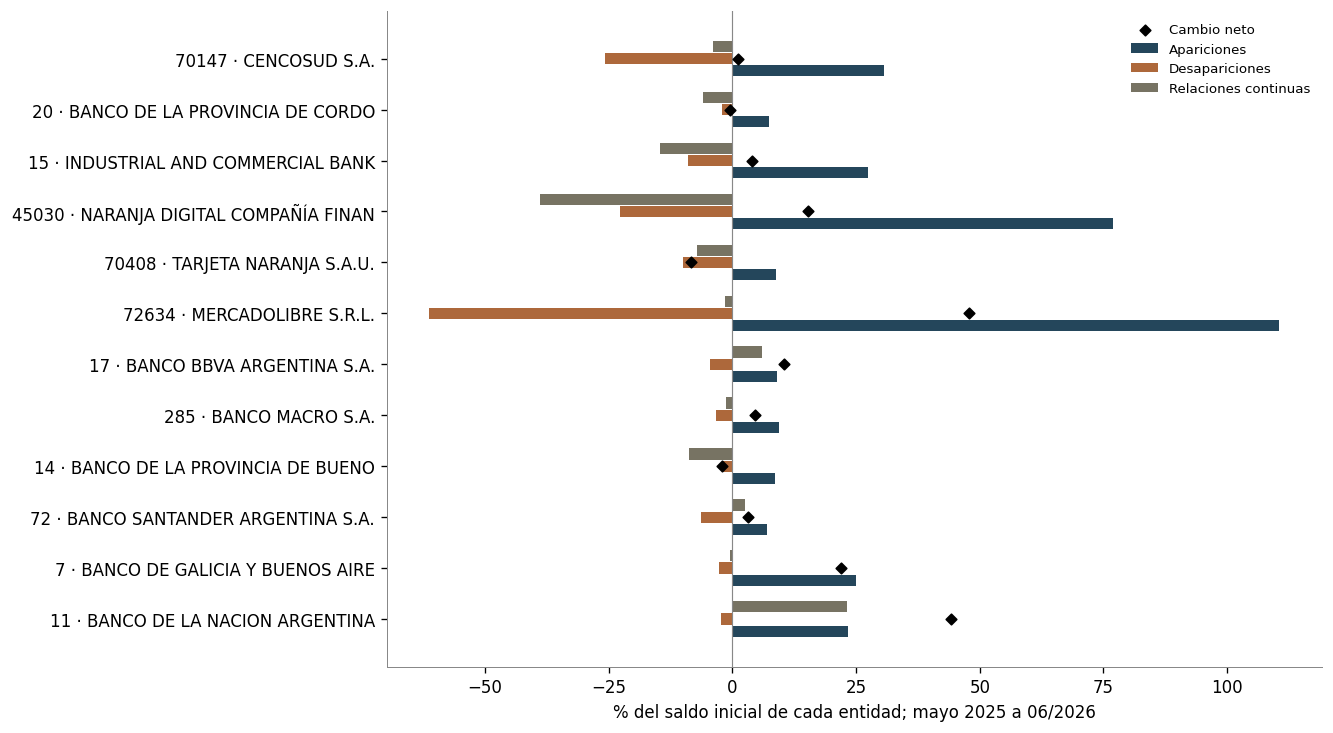

In [10]:
window=t.loc[t.fecha.gt(BASELINE)&t.fecha.le(last)].copy()
components=window.groupby('ent')[['entry_real','exit_real','continuing_change','delta_real']].sum(min_count=1)
initial=entity.loc[entity.fecha.eq(BASELINE)].set_index('ent').amount
components=components.div(initial.replace(0,np.nan),axis=0)*100
final_amount=entity.loc[entity.fecha.eq(last)].set_index('ent').amount*ipc.loc[ipc.fecha.eq(last),'deflactor'].item()
independent_change=100*(final_amount/initial.replace(0,np.nan)-1)
check=components.delta_real.to_frame().join(independent_change.rename('direct')).dropna()
assert np.allclose(check.delta_real,check.direct,atol=1e-7)
components=attach_names(components.reset_index());components.to_csv(OUT/'05_descomposicion_crecimiento.csv',index=False)
d=components.set_index('ent').reindex(focus)
fig,ax=plt.subplots(figsize=(11,6),layout='constrained')
ys=np.arange(len(d))
for offset,col,label,color in [(-.24,'entry_real','Apariciones','#24465B'),(0,'exit_real','Desapariciones','#AD683B'),(.24,'continuing_change','Relaciones continuas','#777363')]:
    ax.barh(ys+offset,d[col],height=.22,label=label,color=color)
ax.scatter(d.delta_real,ys,marker='D',s=20,color='black',label='Cambio neto',zorder=4)
ax.set_yticks(ys,[f'{ent} · {str(name)[:30]}' for ent,name in zip(d.index,d.name)])
ax.axvline(0,color='#888',lw=.7);ax.set_xlabel(f'% del saldo inicial de cada entidad; mayo 2025 a {last:%m/%Y}')
ax.legend(fontsize=8);save_figure(fig,'05_componentes_entidad');plt.show()


## Qué hay detrás de los saltos

Diagnóstico motivado por los gráficos anteriores, no selección de shocks exógenos: Galicia en junio de 2025, Creditech en abril de 2026, ICBC en julio de 2025 y Patagonia en noviembre de 2025. Las dos primeras usan la muestra de personas; las dos últimas, el panel completo de firmas. Se descompone cada cambio mensual en relaciones que aparecen, desaparecen y continúan. La concentración se calcula sobre el cambio **absoluto**, para evitar porcentajes engañosos cuando aumentos y caídas se compensan.

Se conserva la identidad del código. El puente 150/7 se estudió arriba; esta tabla muestra cuánto cambiaría la lectura si se ignorara esa continuidad. Ninguna aparición se denomina automáticamente originación.

In [11]:
episodes=[(7,'person','2025-06-01'),(55294,'person','2026-04-01'),(15,'firm','2025-07-01'),(34,'firm','2025-11-01')]
# Fechar archivos de firmas por contenido, igual que la muestra de personas.
firm_calendar={}
for path in sorted((CENDEU/'firm').glob('*.parquet')):
    dates=con.execute('SELECT DISTINCT year,month FROM read_parquet(?)',[str(path)]).fetchall()
    assert len(dates)==1
    year,month=dates[0];firm_calendar[pd.Timestamp(year,month,1)]=path
record_inputs(paths+list(firm_calendar.values())+list((CENDEU/'lender_month').glob('*.parquet'))+[DATA/'ipc.dta',DATA/'balances_bancos.dta',root/'Data/crosswalks/cendeu_lenders.csv'],'05')
episode_rows=[]
for ent,kind,date in episodes:
    date=pd.Timestamp(date);before=date-pd.offsets.MonthBegin(1)
    mapping=dict(calendar) if kind=='person' else firm_calendar
    d0=ipc.loc[ipc.fecha.eq(before),'deflactor'].item();d1=ipc.loc[ipc.fecha.eq(date),'deflactor'].item()
    result=con.execute((HERE/'sql/episode_changes.sql').read_text(),[str(mapping[before]),ent,str(mapping[date]),ent,d0,d1]).fetchdf()
    result['ent']=ent;result['borrower_type']=kind;result['fecha']=date;episode_rows.append(result)
episode_margins=attach_names(pd.concat(episode_rows,ignore_index=True))
episode_margins.to_csv(OUT/'05_saltos_margenes.csv',index=False)
episode_summary=episode_margins.groupby(['ent','name','borrower_type','fecha']).sum(numeric_only=True).reset_index()
episode_summary['growth_pct']=100*episode_summary.delta_real/episode_summary.before_real
episode_summary['top1_change_pct']=100*episode_summary.top1_abs_change/episode_summary.absolute_change
episode_summary['top10_change_pct']=100*episode_summary.top10_abs_change/episode_summary.absolute_change
episode_summary['top10_stock_pct']=100*episode_summary.top10_stock/episode_summary.after_real
assert np.allclose(episode_summary.delta_real,episode_summary.after_real-episode_summary.before_real)
# Para firmas, contraste directo contra el agregado completo construido por separado.
for row in episode_summary.loc[episode_summary.borrower_type.eq('firm')].itertuples():
    expected=universe.loc[universe.ent.eq(row.ent)&universe.borrower_type.eq('firm')&universe.fecha.eq(row.fecha),'real'].item()
    assert np.isclose(row.after_real,expected)
episode_summary.to_csv(OUT/'05_saltos_concentracion.csv',index=False)
display(episode_summary[['ent','name','borrower_type','fecha','growth_pct','top1_change_pct','top10_change_pct','top10_stock_pct']])


,ent,name,borrower_type,fecha,growth_pct,top1_change_pct,top10_change_pct,top10_stock_pct
0,7,BANCO DE GALICIA Y BUENOS AIRES S.A.,person,2025-06-01,22.01,0.29,2.09,1.44
1,15,INDUSTRIAL AND COMMERCIAL BANK OF CHINA (ARGEN...,firm,2025-07-01,40.94,16.26,56.50,39.88
2,34,BANCO PATAGONIA S.A.,firm,2025-11-01,19.08,8.18,39.36,37.13
3,55294,CREDITECH SA,person,2026-04-01,31.79,0.27,2.23,1.08


### Apariciones frente a variaciones en relaciones existentes

Cada barra es una contribución al cambio mensual dividida por el saldo del mes previo. Las barras suman el cambio neto. El peso de los diez mayores cambios absolutos se indica por separado; no mide participación en la originación.

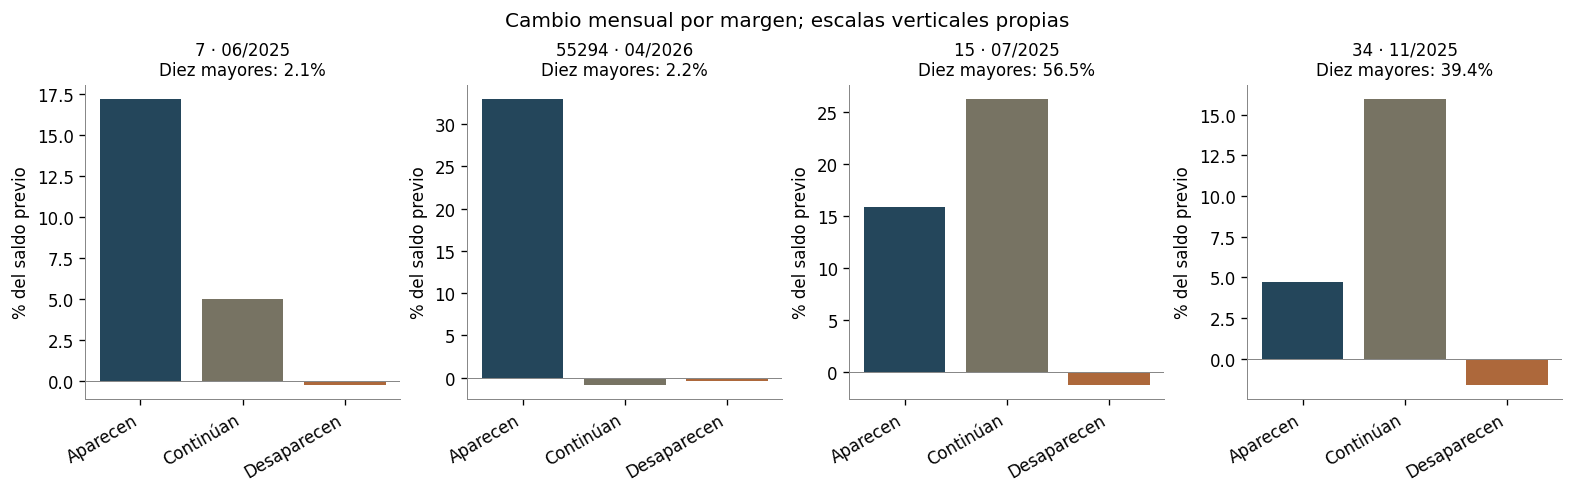

In [12]:
fig,axes=plt.subplots(1,4,figsize=(13,4),layout='constrained')
for ax,(ent,kind,date) in zip(axes,episodes):
    d=episode_margins.loc[episode_margins.ent.eq(ent)].set_index('margin')
    order=['Apariciones','Continuas','Desapariciones']
    contribution=100*d.delta_real.reindex(order,fill_value=0)/d.before_real.sum()
    ax.bar(range(3),contribution,color=['#24465B','#777363','#AD683B'])
    ax.set_xticks(range(3),['Aparecen','Continúan','Desaparecen'],rotation=30,ha='right')
    ax.axhline(0,color='#888',lw=.6)
    r=episode_summary.loc[episode_summary.ent.eq(ent)].iloc[0]
    ax.set_title(f'{ent} · {pd.Timestamp(date):%m/%Y}\nDiez mayores: {r.top10_change_pct:.1f}%',fontsize=10)
    ax.set_ylabel('% del saldo previo')
fig.suptitle('Cambio mensual por margen; escalas verticales propias')
save_figure(fig,'05_saltos_margenes');plt.show()


## La misma persona: entidad focal y sus otros bancos

Cohorte fijada en mayo de 2025, con saldo positivo tanto en cada entidad focal como en al menos un banco comparador. Se conserva a quienes dejan de tener saldo; no se elige a quienes sufrieron una caída. Junio de 2026 es el extremo final con IPC. Los bancos se identifican por `es_banco=1` del balance de mayo; la entidad focal se excluye del comparador. La suma de todos esos códigos bancarios reduce la sensibilidad al cambio 150/7, pero no resuelve todas las cesiones posibles.

Se muestran entidades concretas, sin agruparlas como fintech. Cada cohorte puede compartir personas con las otras y tiene distinta composición. Se clasifica cada cambio según un umbral de ±1% del saldo inicial conjunto. Se reporta el saldo conjunto **focal + otros bancos**, no toda la deuda de la persona: faltan sus otros acreedores no bancarios. Compensación contable no equivale a sustitución causal ni a bienestar.

La tabla agrega además la variación del saldo con **todos los códigos reportantes** de esas mismas personas. Incluye otros prestamistas y posibles garantías: es una comprobación del perímetro, no una medida depurada de deuda neta. Ambas tasas usan sus propios saldos iniciales como denominador.

In [13]:
bank_source=pd.read_stata(DATA/'balances_bancos.dta',convert_categoricals=False)
bank_ids=bank_source.loc[bank_source.ym.eq(BASELINE)&bank_source.es_banco.eq(1),['ent']].copy()
bank_ids.ent=bank_ids.ent.astype(int)
assert bank_ids.ent.is_unique
con.register('bank_ids',bank_ids)
focal_ids=[72634,384,45030,70408,143,55024]
rows=[]
for ent in focal_ids:
    result=con.execute((HERE/'sql/focal_other_credit.sql').read_text(),[str(dict(calendar)[BASELINE]),str(dict(calendar)[last]),ent,ent,ipc.loc[ipc.fecha.eq(last),'deflactor'].item(),ent,ipc.loc[ipc.fecha.eq(last),'deflactor'].item(),ent,ipc.loc[ipc.fecha.eq(last),'deflactor'].item()]).fetchdf()
    result['ent']=ent;rows.append(result)
focal_bins=attach_names(pd.concat(rows,ignore_index=True))
focal_bins['pct']=100*focal_bins.persons/focal_bins.groupby('ent').persons.transform('sum')
assert np.allclose(focal_bins.groupby('ent').pct.sum(),100)
assert np.allclose(focal_bins.end_total,focal_bins.base_total+focal_bins.focal_change+focal_bins.bank_change)
focal_bins.to_csv(OUT/'05_focal_otros_bancos.csv',index=False)
focal_summary=focal_bins.groupby(['ent','name'])[['persons','base_total','end_total','all_before','all_after','focal_change','bank_change','focal_no_balance','banks_no_balance']].sum().reset_index()
for col in ['focal_change','bank_change']:focal_summary[col+'_pp']=100*focal_summary[col]/focal_summary.base_total
focal_summary['joint_growth_pct']=100*(focal_summary.end_total/focal_summary.base_total-1)
focal_summary['all_reported_growth_pct']=100*(focal_summary.all_after/focal_summary.all_before-1)
focal_summary['rest_change']=focal_summary.all_after-focal_summary.all_before-focal_summary.focal_change-focal_summary.bank_change
focal_summary.to_csv(OUT/'05_focal_resumen.csv',index=False)
display(focal_summary[['ent','name','persons','focal_change_pp','bank_change_pp','joint_growth_pct','all_reported_growth_pct']])


,ent,name,persons,focal_change_pp,bank_change_pp,joint_growth_pct,all_reported_growth_pct
0,143,BRUBANK S.A.U.,2456,-5.61,5.78,0.17,1.84
1,384,UALA BANK S.A.U.,8835,-8.14,2.12,-6.02,-5.84
2,45030,NARANJA DIGITAL COMPAÑÍA FINANCIERA S.A.U.,46375,-4.37,0.65,-3.73,-2.88
3,55024,CREDICUOTAS CONSUMO S.A.,10141,-10.44,-6.41,-16.85,-14.57
4,70408,TARJETA NARANJA S.A.U.,117811,-3.16,2.37,-0.78,1.00
5,72634,MERCADOLIBRE S.R.L.,140159,-1.38,2.86,1.48,2.21


### Cambios conjuntos y magnitud

El primer gráfico presenta los nueve estados posibles sobre toda la cohorte. El segundo conserva magnitudes: una compensación pequeña no equivale a recuperación del saldo conjunto. La clasificación de signos pierde información de tamaño, por eso se muestran ambos.

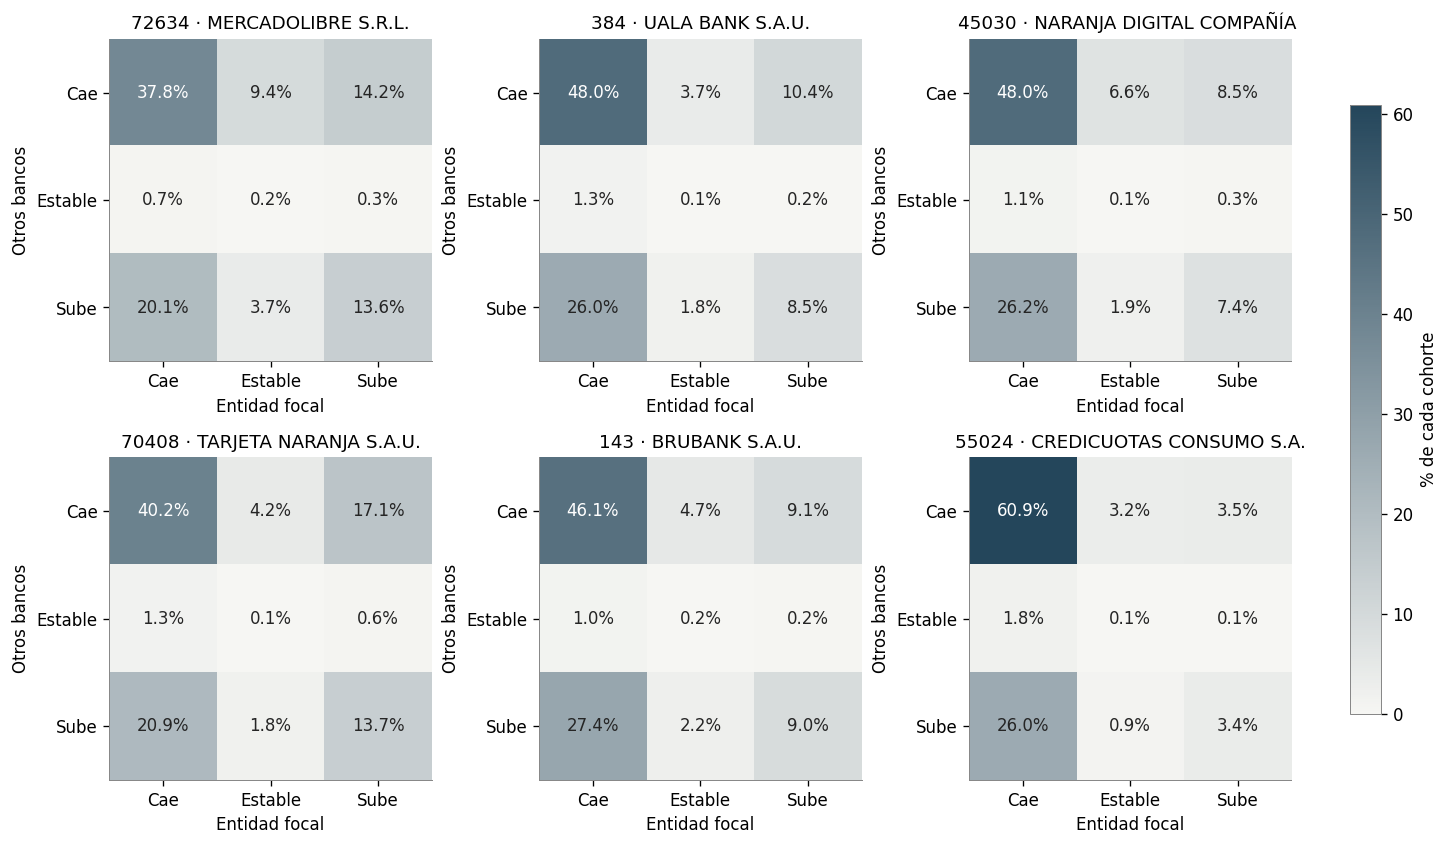

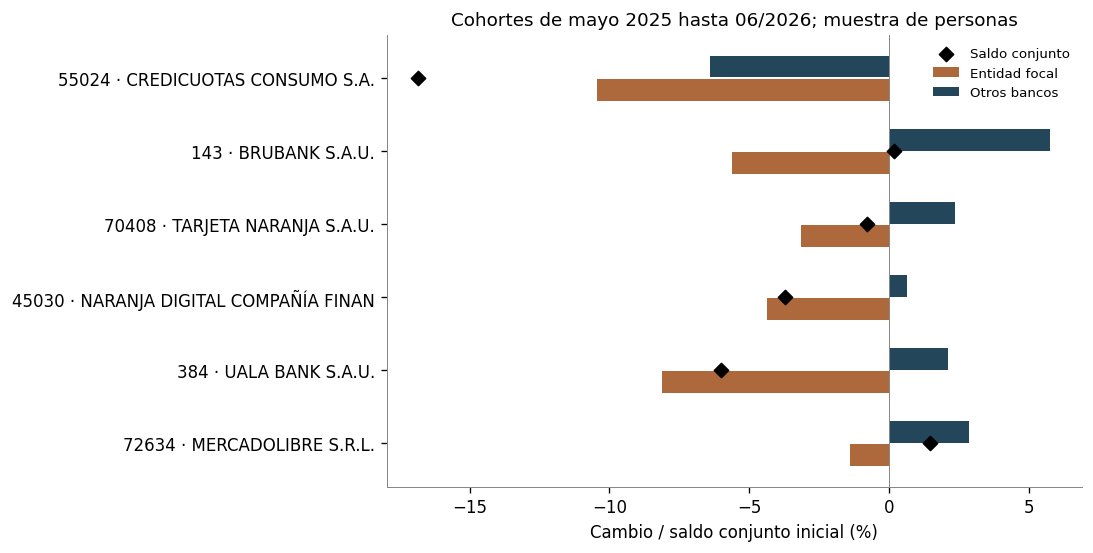

In [14]:
from matplotlib.colors import LinearSegmentedColormap
fig,axes=plt.subplots(2,3,figsize=(12,7),layout='constrained')
order=['Cae','Estable','Sube'];cmap=LinearSegmentedColormap.from_list('neutral_blue',['#f6f6f3','#24465B'])
vmax=focal_bins.pct.max()
for ax,ent in zip(axes.flat,focal_ids):
    d=focal_bins.loc[focal_bins.ent.eq(ent)]
    matrix=d.pivot(index='bank_bin',columns='focal_bin',values='pct').reindex(index=order,columns=order).fillna(0)
    im=ax.imshow(matrix,vmin=0,vmax=vmax,cmap=cmap)
    for i in range(3):
        for j in range(3):
            val=matrix.iloc[i,j];ax.text(j,i,f'{val:.1f}%',ha='center',va='center',color='white' if val>vmax*.55 else '#252525')
    ax.set_xticks(range(3),order);ax.set_yticks(range(3),order)
    ax.set(title=f'{ent} · {d.name.iloc[0][:25]}',xlabel='Entidad focal',ylabel='Otros bancos')
fig.colorbar(im,ax=axes,label='% de cada cohorte',shrink=.8)
save_figure(fig,'05_focal_matrices');plt.show()
fig,ax=plt.subplots(figsize=(9,4.5),layout='constrained')
d=focal_summary.set_index('ent').reindex(focal_ids);y=np.arange(len(d))
ax.barh(y-.16,d.focal_change_pp,height=.3,label='Entidad focal',color='#AD683B')
ax.barh(y+.16,d.bank_change_pp,height=.3,label='Otros bancos',color='#24465B')
ax.scatter(d.joint_growth_pct,y,color='black',marker='D',label='Saldo conjunto',zorder=4)
ax.set_yticks(y,[f'{ent} · {name[:30]}' for ent,name in zip(d.index,d.name)])
ax.axvline(0,color='#888',lw=.6);ax.set_xlabel('Cambio / saldo conjunto inicial (%)');ax.legend(fontsize=8)
ax.set_title(f'Cohortes de mayo 2025 hasta {last:%m/%Y}; muestra de personas')
save_figure(fig,'05_focal_magnitudes');plt.show()


## Puente con balances: exposiciones previas, sin tratamiento impuesto

Cruce por código con el balance de mayo de 2025. Efectivo/activo, títulos/activo y depósitos/activo describen estructura; no se llama liquidez libre a todos los títulos. Se usa el último mes común con IPC, CENDEU y balances. El cambio de deuda CENDEU corresponde a personas o firmas, mientras que el fondeo es de toda la entidad: no son sectores contablemente idénticos. Se exportan cruces para explorar, sin elegir exposición por significatividad. Los ingresos por tarjetas no se convierten en participación de stock de tarjetas.

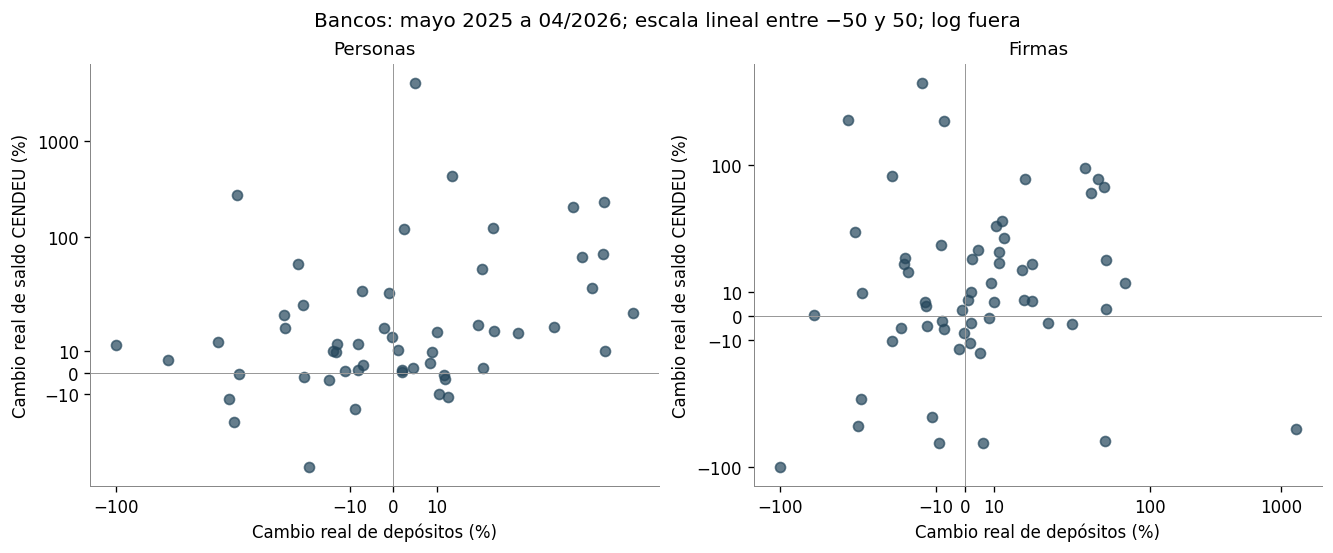

,último_mes_común,bancos_con_depositos,entidades_sin_balance_en_cruce
0,2026-04-01,59,489


In [15]:
balance=pd.read_stata(DATA/'balances_bancos.dta',convert_categoricals=False)
assert not balance.duplicated(['ent','ym']).any()
balance['ent']=balance.ent.astype(int)
common_end=min(last,balance.ym.max())
pre=balance.loc[balance.ym.eq(BASELINE),['ent','nombre','es_banco','activo','efectivo','titulos','depositos']].copy()
for col in ['efectivo','titulos','depositos']: pre[col+'_share']=100*pre[col]/pre.activo.replace(0,np.nan)
end=balance.loc[balance.ym.eq(common_end),['ent','depositos']].rename(columns={'depositos':'depositos_end'})
pre=pre.merge(end,on='ent',how='left',validate='one_to_one')
end_deflator=ipc.loc[ipc.fecha.eq(common_end),'deflactor'].item()
pre['dep_growth']=100*(pre.depositos_end*end_deflator/pre.depositos.replace(0,np.nan)-1)
credit_base=universe.loc[universe.fecha.eq(BASELINE),['ent','borrower_type','real']].rename(columns={'real':'credit_base'})
credit_end=universe.loc[universe.fecha.eq(common_end),['ent','borrower_type','real']].rename(columns={'real':'credit_end'})
bridge=credit_base.merge(credit_end,on=['ent','borrower_type'],how='outer',validate='one_to_one').merge(pre,on='ent',how='left',validate='many_to_one')
bridge['credit_growth']=100*(bridge.credit_end/bridge.credit_base.replace(0,np.nan)-1)
bridge.to_csv(OUT/'05_puente_balances.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(11,4.5),layout='constrained')
for ax,kind in zip(axes,['person','firm']):
    d=bridge.loc[bridge.borrower_type.eq(kind)&bridge.es_banco.eq(1)].dropna(subset=['dep_growth','credit_growth'])
    ax.scatter(d.dep_growth,d.credit_growth,color='#24465B',alpha=.7)
    ax.set_xscale('symlog',linthresh=50); ax.set_yscale('symlog',linthresh=50)
    from matplotlib.ticker import ScalarFormatter
    for axis in [ax.xaxis,ax.yaxis]: axis.set_major_formatter(ScalarFormatter())
    ax.axhline(0,color='#999',lw=.6);ax.axvline(0,color='#999',lw=.6)
    ax.set(title='Personas' if kind=='person' else 'Firmas',xlabel='Cambio real de depósitos (%)',ylabel='Cambio real de saldo CENDEU (%)')
fig.suptitle(f'Bancos: mayo 2025 a {common_end:%m/%Y}; escala lineal entre −50 y 50; log fuera')
save_figure(fig,'05_depositos_credito');plt.show()
display(pd.DataFrame({'último_mes_común':[common_end],'bancos_con_depositos':[pre.loc[pre.es_banco.eq(1),'dep_growth'].notna().sum()],'entidades_sin_balance_en_cruce':[bridge.loc[bridge.nombre.isna(),'ent'].nunique()]}))
con.close()


## Lectura y agenda

Las clasificaciones se construirán después de observar las entidades, combinando atributos separados y fechados: licencia, fondeo, productos y tecnología de cobro. No se infiere uso de billetera por tener deuda con su grupo. Cambios de código, fusiones y fideicomisos necesitan puentes documentales antes de unir series.

Esta exploración permite elegir entre preguntas de expansión de clientes, deterioro, asimetrías de reporte y transmisión del fondeo. No identifica ninguna por sí sola. Los ceros son resultados observados del reshape, no causas verificadas; `legal` es un código original, no un indicador judicial validado; no se interpreta como inicio de juicio. La comparabilidad dentro de la persona no elimina diferencias de producto o de contrato.